#Load dataset

In [1]:
import os, re, time, random, copy
from datasets import load_dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from collections import Counter
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


In [2]:
ds = load_dataset("stanfordnlp/imdb")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [3]:
ds_train = ds["train"]
ds_test = ds["test"]
ds_unsupervised = ds["unsupervised"]

train_df = pd.DataFrame({"text": ds_train["text"], "label": ds_train["label"]})
test_df = pd.DataFrame({"text": ds_test["text"], "label": ds_test["label"]})
train_df, val_df = train_test_split(train_df, test_size=0.2, random_state=SEED, stratify=train_df["label"])
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


,metric,value
0,train samples,20000.000
1,validation samples,5000.000
2,test samples,25000.000
3,classes,2.000
4,missing text,0.000
5,missing labels,0.000
6,duplicate train texts,59.000
7,min length,10.000
8,median length,174.000
9,mean length,233.138


,count
label,
0,10000
1,10000


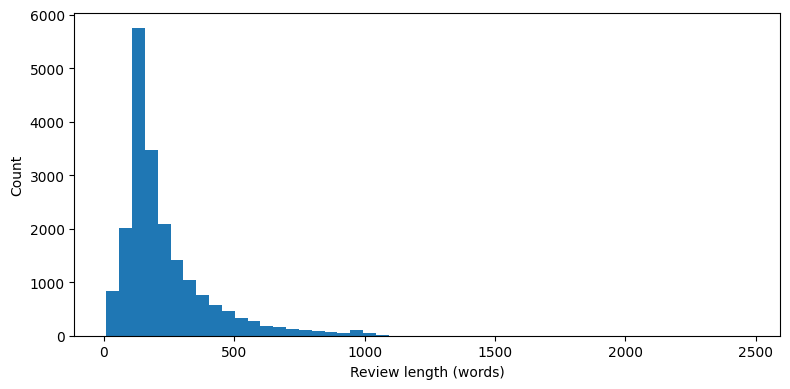

In [4]:
lengths = train_df["text"].str.split().str.len()
dataset_stats = pd.DataFrame({
    "metric": ["train samples", "validation samples", "test samples", "classes", "missing text", "missing labels", "duplicate train texts", "min length", "median length", "mean length", "max length"],
    "value": [len(train_df), len(val_df), len(test_df), train_df["label"].nunique(), train_df["text"].isna().sum(), train_df["label"].isna().sum(), train_df["text"].duplicated().sum(), lengths.min(), lengths.median(), lengths.mean(), lengths.max()]
})
display(dataset_stats)
display(train_df["label"].value_counts().sort_index().rename("count").to_frame())
plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=50)
plt.xlabel("Review length (words)")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("sequence_length_histogram.png", dpi=150)
plt.show()

In [5]:
def tokenize(text):
    return re.findall(r"\b\w+\b|[^\w\s]", str(text).lower())

VOCAB_SIZE = 20000
PAD_ID, UNK_ID = 0, 1
counter = Counter(token for text in train_df["text"] for token in tokenize(text))
vocab = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}
vocab.update({word: i + 2 for i, (word, _) in enumerate(counter.most_common(VOCAB_SIZE - 2))})
vocab_size = len(vocab)

def encode_text(text, max_length):
    ids = [vocab.get(token, UNK_ID) for token in tokenize(text)[:max_length]]
    return ids + [PAD_ID] * (max_length - len(ids))

class ReviewDataset(Dataset):
    def __init__(self, frame, max_length):
        self.texts = frame["text"].tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.max_length = max_length
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return torch.tensor(encode_text(self.texts[idx], self.max_length)), torch.tensor(self.labels[idx], dtype=torch.long)

def make_loaders(max_length, batch_size=128):
    train_loader = DataLoader(ReviewDataset(train_df, max_length), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(ReviewDataset(val_df, max_length), batch_size=batch_size)
    test_loader = DataLoader(ReviewDataset(test_df, max_length), batch_size=batch_size)
    return train_loader, val_loader, test_loader

print("Vocabulary size:", vocab_size)

Vocabulary size: 20000


In [6]:
class SimpleRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_layer = nn.Linear(input_size, hidden_size, bias=True)
        self.hidden_layer = nn.Linear(hidden_size, hidden_size, bias=False)
    def forward(self, x_t, h_prev):
        return torch.tanh(self.input_layer(x_t) + self.hidden_layer(h_prev))

x_t = torch.tensor([[1.0], [0.0]])
h_prev = torch.tensor([[0.5], [0.2]])
W_xh = torch.tensor([[0.5, 0.2], [0.1, 0.4]])
W_hh = torch.tensor([[0.3, 0.1], [0.2, 0.5]])
a_t = W_xh @ x_t + W_hh @ h_prev
h_t = torch.tanh(a_t)
print("a_t =", a_t.flatten().tolist())
print("h_t =", h_t.flatten().tolist())

a_t = [0.6700000166893005, 0.30000001192092896]
h_t = [0.5849798917770386, 0.29131263494491577]


In [7]:
class SequenceClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=100, hidden_size=128, model_type="LSTM", padding_idx=PAD_ID):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=padding_idx)
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[model_type]
        self.recurrent = rnn_cls(embedding_dim, hidden_size, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(hidden_size, 2)
    def forward(self, x):
        embedded = self.embedding(x)
        _, state = self.recurrent(embedded)
        h = state[0] if isinstance(state, tuple) else state
        return self.classifier(self.dropout(h[-1]))

def metric_values(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }

def train_model(model_type="LSTM", max_length=100, epochs=3, batch_size=128, lr=1e-3):
    train_loader, val_loader, test_loader = make_loaders(max_length, batch_size)
    model = SequenceClassifier(vocab_size, model_type=model_type).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = []
    start = time.time()
    best_state, best_f1 = None, -1
    for epoch in range(epochs):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_losses.append(loss.item())
        model.eval()
        val_losses, ys, preds = [], [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                val_losses.append(criterion(logits, yb).item())
                preds.extend(logits.argmax(1).cpu().numpy())
                ys.extend(yb.numpy())
        scores = metric_values(ys, preds)
        history.append({"epoch": epoch + 1, "train_loss": np.mean(train_losses), "val_loss": np.mean(val_losses), **scores})
        if scores["f1"] > best_f1:
            best_f1 = scores["f1"]
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    elapsed = time.time() - start
    model.eval()
    ys, preds = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            logits = model(xb.to(DEVICE))
            preds.extend(logits.argmax(1).cpu().numpy())
            ys.extend(yb.numpy())
    result = {"model": model_type, "max_length": max_length, "parameters": sum(p.numel() for p in model.parameters()), "training_time_sec": elapsed, **metric_values(ys, preds)}
    return model, pd.DataFrame(history), result, (np.array(ys), np.array(preds))

In [8]:
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2, max_df=0.95)
X_train = tfidf.fit_transform(train_df["text"])
X_val = tfidf.transform(val_df["text"])
X_test = tfidf.transform(test_df["text"])
baseline = LogisticRegression(max_iter=1000, random_state=SEED)
start = time.time()
baseline.fit(X_train, train_df["label"])
baseline_time = time.time() - start
baseline_pred = baseline.predict(X_test)
baseline_result = {"model": "TF-IDF + LogisticRegression", "max_length": np.nan, "parameters": len(baseline.coef_.ravel()) + len(baseline.intercept_), "training_time_sec": baseline_time, **metric_values(test_df["label"], baseline_pred)}
print(baseline_result)

{'model': 'TF-IDF + LogisticRegression', 'max_length': nan, 'parameters': 20001, 'training_time_sec': 12.59077262878418, 'accuracy': 0.89096, 'precision': 0.8870584508157769, 'recall': 0.896, 'f1': 0.8915068056992757}


In [9]:
sequence_results = []
histories = {}
models = {}
predictions = {}
for model_type in ["RNN", "LSTM", "GRU"]:
    model, history, result, test_predictions = train_model(model_type=model_type, max_length=100, epochs=3)
    models[model_type] = model
    histories[model_type] = history
    sequence_results.append(result)
    predictions[model_type] = test_predictions
    print(result)

{'model': 'RNN', 'max_length': 100, 'parameters': 2029698, 'training_time_sec': 54.80752611160278, 'accuracy': 0.60212, 'precision': 0.6419753086419753, 'recall': 0.46176, 'f1': 0.537155088176446}
{'model': 'LSTM', 'max_length': 100, 'parameters': 2118018, 'training_time_sec': 69.81628918647766, 'accuracy': 0.69284, 'precision': 0.6470265324794144, 'recall': 0.84864, 'f1': 0.7342446790102094}
{'model': 'GRU', 'max_length': 100, 'parameters': 2088578, 'training_time_sec': 130.10307145118713, 'accuracy': 0.74984, 'precision': 0.7285567915690867, 'recall': 0.7964, 'f1': 0.7609692707537073}


In [10]:
length_results = []
length_histories = {}
for max_length in [50, 100, 200]:
    model, history, result, test_predictions = train_model(model_type="LSTM", max_length=max_length, epochs=3)
    length_results.append(result)
    length_histories[max_length] = history
    print(result)

{'model': 'LSTM', 'max_length': 50, 'parameters': 2118018, 'training_time_sec': 38.73812484741211, 'accuracy': 0.70988, 'precision': 0.7090604829070045, 'recall': 0.71184, 'f1': 0.7104475228552039}
{'model': 'LSTM', 'max_length': 100, 'parameters': 2118018, 'training_time_sec': 69.25020599365234, 'accuracy': 0.61948, 'precision': 0.5860955784861935, 'recall': 0.81336, 'f1': 0.6812744999497437}
{'model': 'LSTM', 'max_length': 200, 'parameters': 2118018, 'training_time_sec': 121.94229865074158, 'accuracy': 0.52944, 'precision': 0.5241121740269952, 'recall': 0.63992, 'f1': 0.5762553130177941}


In [11]:
results_df = pd.DataFrame([baseline_result] + sequence_results)
length_df = pd.DataFrame(length_results)
display(results_df)
display(length_df)
results_df.to_csv("results.csv", index=False)
length_df.to_csv("sequence_length_results.csv", index=False)

,model,max_length,parameters,training_time_sec,accuracy,precision,recall,f1
0,TF-IDF + LogisticRegression,NaN,20001,12.590773,0.89096,0.887058,0.89600,0.891507
1,RNN,100.0,2029698,54.807526,0.60212,0.641975,0.46176,0.537155
2,LSTM,100.0,2118018,69.816289,0.69284,0.647027,0.84864,0.734245
3,GRU,100.0,2088578,130.103071,0.74984,0.728557,0.79640,0.760969


,model,max_length,parameters,training_time_sec,accuracy,precision,recall,f1
0,LSTM,50,2118018,38.738125,0.70988,0.709060,0.71184,0.710448
1,LSTM,100,2118018,69.250206,0.61948,0.586096,0.81336,0.681274
2,LSTM,200,2118018,121.942299,0.52944,0.524112,0.63992,0.576255


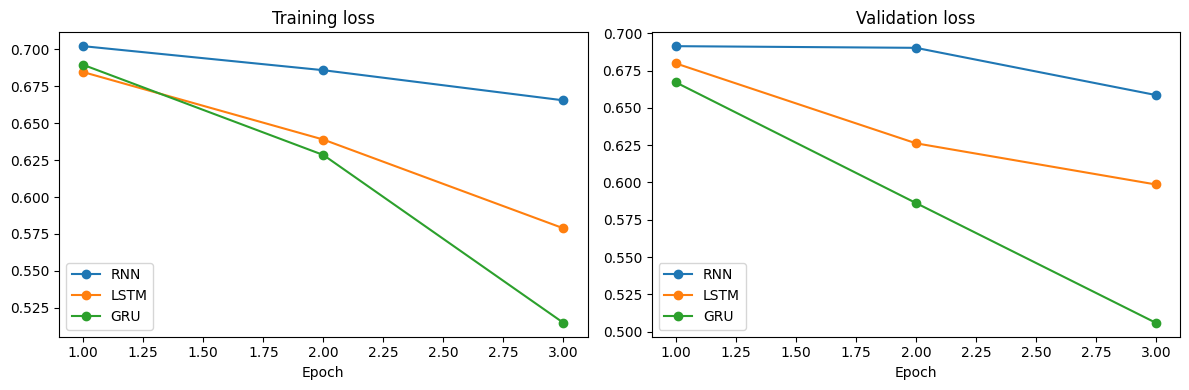

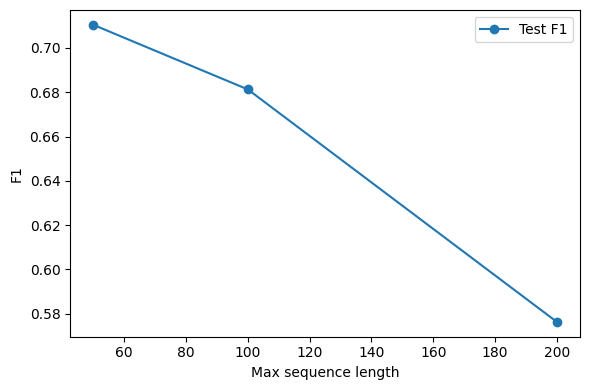

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    axes[0].plot(history["epoch"], history["train_loss"], marker="o", label=name)
    axes[1].plot(history["epoch"], history["val_loss"], marker="o", label=name)
axes[0].set_title("Training loss")
axes[1].set_title("Validation loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150)
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(length_df["max_length"], length_df["f1"], marker="o", label="Test F1")
plt.xlabel("Max sequence length")
plt.ylabel("F1")
plt.legend()
plt.tight_layout()
plt.savefig("sequence_length_f1.png", dpi=150)
plt.show()

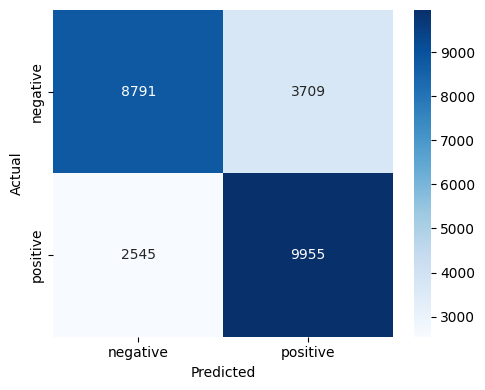

              precision    recall  f1-score   support

    negative       0.78      0.70      0.74     12500
    positive       0.73      0.80      0.76     12500

    accuracy                           0.75     25000
   macro avg       0.75      0.75      0.75     25000
weighted avg       0.75      0.75      0.75     25000



In [13]:
best_name = results_df.loc[results_df["model"].isin(["RNN", "LSTM", "GRU"]), "f1"].idxmax()
best_model_name = results_df.loc[best_name, "model"]
y_true, y_pred = predictions[best_model_name]
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()
print(classification_report(y_true, y_pred, target_names=["negative", "positive"], zero_division=0))

In [14]:
error_df = test_df[["text", "label"]].copy()
error_df["predicted"] = y_pred
error_df["actual_label"] = error_df["label"].map({0: "negative", 1: "positive"})
error_df["predicted_label"] = error_df["predicted"].map({0: "negative", 1: "positive"})
error_df["correct"] = error_df["label"] == error_df["predicted"]
display(error_df[error_df["correct"]].head(3)[["text", "actual_label", "predicted_label"]])
display(error_df[~error_df["correct"]].head(3)[["text", "actual_label", "predicted_label"]])
error_df.to_csv("error_analysis_examples.csv", index=False)

,text,actual_label,predicted_label
2,its a totally average film with a few semi-alr...,negative,negative
3,STAR RATING: ***** Saturday Night **** Friday ...,negative,negative
4,"First off let me say, If you haven't enjoyed a...",negative,negative


,text,actual_label,predicted_label
0,I love sci-fi and am willing to put up with a ...,negative,positive
1,"Worth the entertainment value of a rental, esp...",negative,positive
6,Isaac Florentine has made some of the best wes...,negative,positive


In [15]:
def predict_review(text, model_name="LSTM", max_length=100):
    model = models[model_name]
    ids = torch.tensor([encode_text(text, max_length)], dtype=torch.long).to(DEVICE)
    model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(model(ids), dim=1)[0].cpu().numpy()
    label = int(probabilities.argmax())
    return {"prediction": "positive" if label == 1 else "negative", "probability": float(probabilities[label]), "class_probabilities": {"negative": float(probabilities[0]), "positive": float(probabilities[1])}}

for sample in [
    "I really enjoyed this movie.",
    "This is a long and complicated review with many details about the story, acting, direction and music.",
    "The movie was not good.",
    "I expected the movie to be bad, but it was surprisingly good."
]:
    print(sample, predict_review(sample))

I really enjoyed this movie. {'prediction': 'positive', 'probability': 0.9110304713249207, 'class_probabilities': {'negative': 0.08896958082914352, 'positive': 0.9110304713249207}}
This is a long and complicated review with many details about the story, acting, direction and music. {'prediction': 'positive', 'probability': 0.9110304713249207, 'class_probabilities': {'negative': 0.08896960318088531, 'positive': 0.9110304713249207}}
The movie was not good. {'prediction': 'negative', 'probability': 0.874838650226593, 'class_probabilities': {'negative': 0.874838650226593, 'positive': 0.12516139447689056}}
I expected the movie to be bad, but it was surprisingly good. {'prediction': 'positive', 'probability': 0.9110227227210999, 'class_probabilities': {'negative': 0.08897731453180313, 'positive': 0.9110227227210999}}
